# Analyse Expérimentale Huffman Dynamique

### imports

In [ ]:
import math
import random
import string
from collections import Counter
import matplotlib.pyplot as plt
import sys
from glob import glob
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


## Fonctions pour graphes

In [ ]:
def show_ratio(txt_rel, bin_rel, label=None):
    txt_path = os.path.join("..", *txt_rel.split("/"))
    bin_path = os.path.join("..", *bin_rel.split("/"))
    txt_size = os.path.getsize(txt_path) if os.path.exists(txt_path) else 0
    bin_size = os.path.getsize(bin_path) if os.path.exists(bin_path) else 0
    if not txt_size or not bin_size:
        print(f"{label or txt_rel}: fichiers introuvables ou taille nulle")
        return
    ratio = bin_size / txt_size
    taux = 1 - ratio
    facteur = txt_size / bin_size
    name = label or os.path.basename(txt_path)
    print(f"{name}: {bin_size}/{txt_size} octets | taux: {taux:.2%} | facteur: {facteur:.2f}x")

In [ ]:
def load_log_file(filename):
    """
    Charge un fichier de log (compression.txt ou decompression.txt)
    
    Format attendu : input_file;output_file;input_size;output_size;rate;time_ms
    """
    columns = ['input_file', 'output_file', 'input_size', 'output_size', 'rate', 'time_ms']
    df = pd.read_csv(filename, sep=';', names=columns, encoding='utf-8')
    return df

In [ ]:
def plot_time_size():
    """
    Crée des graphiques montrant le temps de compression et décompression en fonction de la taille des fichiers
    """
    # Charger les données
    df_compression = load_log_file('../compression.txt')
    df_decompression = load_log_file('../decompression.txt')
    
    # Créer une figure avec 2 sous-graphiques
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ========== GRAPHIQUE 1 : Compression ==========
    ax1 = axes[0]
    
    # Scatter plot
    ax1.scatter(df_compression['input_size'], df_compression['time_ms'], 
                alpha=0.6, s=50, color='blue', label='Points de données')
    
    # Ligne de tendance (régression linéaire)
    z = np.polyfit(df_compression['input_size'], df_compression['time_ms'], 1)
    p = np.poly1d(z)
    ax1.plot(df_compression['input_size'], p(df_compression['input_size']), 
             "r--", linewidth=2, label=f'Tendance: y={z[0]:.6f}x+{z[1]:.2f}')
    
    ax1.set_xlabel('Taille du fichier (octets)', fontsize=12)
    ax1.set_ylabel('Temps de compression (ms)', fontsize=12)
    ax1.set_title('Temps de compression = f(Taille fichier)', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # ========== GRAPHIQUE 2 : Décompression ==========
    ax2 = axes[1]
    
    # Scatter plot
    ax2.scatter(df_decompression['input_size'], df_decompression['time_ms'], 
                alpha=0.6, s=50, color='green', label='Points de données')
    
    # Ligne de tendance
    z2 = np.polyfit(df_decompression['input_size'], df_decompression['time_ms'], 1)
    p2 = np.poly1d(z2)
    ax2.plot(df_decompression['input_size'], p2(df_decompression['input_size']), 
             "r--", linewidth=2, label=f'Tendance: y={z2[0]:.6f}x+{z2[1]:.2f}')
    
    ax2.set_xlabel('Taille du fichier compressé (octets)', fontsize=12)
    ax2.set_ylabel('Temps de décompression (ms)', fontsize=12)
    ax2.set_title('Temps de décompression = f(Taille fichier)', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.tight_layout()
    plt.savefig('temps_taille.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : temps_taille.png")
    plt.show()


def plot_comparison():
    """
    Compare compression et décompression sur le même graphique
    """
    # Charger les données
    df_comp = load_log_file('../compression.txt')
    df_decomp = load_log_file('../decompression.txt')
    
    plt.figure(figsize=(10, 6))
    
    # Compression
    plt.scatter(df_comp['input_size'], df_comp['time_ms'], 
                alpha=0.6, s=50, color='blue', label='Compression')
    
    # Décompression
    plt.scatter(df_decomp['input_size'], df_decomp['time_ms'], 
                alpha=0.6, s=50, color='green', label='Décompression')
    
    plt.xlabel('Taille du fichier (octets)', fontsize=12)
    plt.ylabel('Temps (ms)', fontsize=12)
    plt.title('Comparaison Compression vs Décompression', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('comparaison_temps.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : comparaison_temps.png")
    plt.show()


def plot_compression_rate():
    """
    Graphique du taux de compression en fonction de la taille
    """
    df = load_log_file('../compression.txt')
    
    plt.figure(figsize=(10, 6))
    
    plt.scatter(df['input_size'], df['rate'], alpha=0.6, s=50, color='purple')
    
    # Ligne horizontale à 1.0 (pas de compression)
    plt.axhline(y=1.0, color='r', linestyle='--', linewidth=1, label='Pas de compression (rate=1.0)')
    
    plt.xlabel('Taille du fichier original (octets)', fontsize=12)
    plt.ylabel('Taux de compression', fontsize=12)
    plt.title('Taux de compression = f(Taille fichier)', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('taux_compression.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : taux_compression.png")
    plt.show()


def plot_all_stats():
    """
    Crée une figure avec 4 graphiques pour une vue complète
    """
    df_comp = load_log_file('../compression.txt')
    df_decomp = load_log_file('../decompression.txt')
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Temps compression en fonction taille
    axes[0, 0].scatter(df_comp['input_size'], df_comp['time_ms'], alpha=0.6, color='blue')
    axes[0, 0].set_xlabel('Taille (octets)')
    axes[0, 0].set_ylabel('Temps (ms)')
    axes[0, 0].set_title('Compression : Temps compression = f(Taille)')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Temps décompression ven fonction taille
    axes[0, 1].scatter(df_decomp['input_size'], df_decomp['time_ms'], alpha=0.6, color='green')
    axes[0, 1].set_xlabel('Taille (octets)')
    axes[0, 1].set_ylabel('Temps (ms)')
    axes[0, 1].set_title('Décompression : Temps décompression = f(Taille)')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Taux de compression en fonction taille
    axes[1, 0].scatter(df_comp['input_size'], df_comp['rate'], alpha=0.6, color='purple')
    axes[1, 0].axhline(y=1.0, color='r', linestyle='--', linewidth=1)
    axes[1, 0].set_xlabel('Taille (octets)')
    axes[1, 0].set_ylabel('Taux de compression')
    axes[1, 0].set_title('Taux de compression = f(Taille)')
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Distribution des taux de compression
    axes[1, 1].hist(df_comp['rate'], bins=20, alpha=0.7, color='orange', edgecolor='black')
    axes[1, 1].axvline(x=df_comp['rate'].mean(), color='r', linestyle='--', 
                       linewidth=2, label=f'Moyenne: {df_comp["rate"].mean():.3f}')
    axes[1, 1].set_xlabel('Taux de compression')
    axes[1, 1].set_ylabel('Fréquence')
    axes[1, 1].set_title('Distribution des taux de compression')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('analyse_complete.png', dpi=300, bbox_inches='tight')
    print("Graphique sauvegardé : analyse_complete.png")
    plt.show()


def print_statistics():
    """
    Affiche des statistiques résumées
    """
    df_comp = load_log_file('../compression.txt')
    df_decomp = load_log_file('../decompression.txt')
    
    print("=" * 30)
    print("STATISTIQUES DE COMPRESSION")
    print("=" * 30)
    print(f"Nombre de fichiers : {len(df_comp)}")
    print(f"Taux moyen : {df_comp['rate'].mean():.5f}")
    print(f"Temps moyen : {df_comp['time_ms'].mean():.2f} ms")
    print(f"Taille moyenne entrée : {df_comp['input_size'].mean():.0f} octets")
    print(f"Réduction moyenne : {(1 - df_comp['rate'].mean()) * 100:.2f}%")
    
    print("\n" + "=" * 30)
    print("STATISTIQUES DE DÉCOMPRESSION")
    print("=" * 30)
    print(f"Nombre de fichiers : {len(df_decomp)}")
    print(f"Temps moyen : {df_decomp['time_ms'].mean():.2f} ms")
    
    # Comparaison vitesse
    ratio = df_comp['time_ms'].mean() / df_decomp['time_ms'].mean()
    print(f"\nLa décompression est {ratio:.2f}x plus rapide que la compression")


## Résultats expérimentaux sur fichiers textuels existants (question 8) 
Bibliothèques de textes utilisée : projet Gutenberg, cf rapport pour sources

Si on veut uniquement les informations de compression des fichiers textuels  


In [ ]:
!echo -n > ../compression.txt && echo -n > ../decompression.txt

#### Texte Français (NdP - Hugo) -- autour de 15 secondes

In [10]:
!../compresser ../texts/francais.txt ../texts/bintexts/francais.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/francais.huff
Compression ../texts/francais.txt ...
Fichier encodé avec succès: ../texts/francais.txt -> ../texts/bintexts/francais.huff


In [ ]:
# Français (NdP - Hugo)
show_ratio("texts/francais.txt", "texts/bintexts/francais.bin", label="Français (Hugo)")

#### Texte Français 2 (Blaise Pascal) -- autour de 4 secondes

In [11]:
!../compresser ../texts/Blaise_Pascal/Blaise_Pascal.txt ../texts/bintexts/Blaise_Pascal.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/Blaise_Pascal.huff
Compression ../texts/Blaise_Pascal/Blaise_Pascal.txt ...
Fichier encodé avec succès: ../texts/Blaise_Pascal/Blaise_Pascal.txt -> ../texts/bintexts/Blaise_Pascal.huff


In [ ]:
# Blaise Pascal
show_ratio("texts/Blaise_Pascal/Blaise_Pascal.txt", "texts/Blaise_Pascal/Blaise_Pascal.txt.huff", label="Blaise Pascal")

#### Texte Anglais -- autour de 12 secondes

In [12]:
!../compresser ../texts/anglais.txt ../texts/bintexts/anglais.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/anglais.huff
Compression ../texts/anglais.txt ...
Fichier encodé avec succès: ../texts/anglais.txt -> ../texts/bintexts/anglais.huff


In [ ]:
show_ratio("texts/anglais.txt", "texts/bintexts/anglais.bin", label="Anglais")

#### Texte Grec -- autour de 45 secondes

In [13]:
!../compresser ../texts/grec.txt ../texts/bintexts/grec.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/grec.huff
Compression ../texts/grec.txt ...
Fichier encodé avec succès: ../texts/grec.txt -> ../texts/bintexts/grec.huff


In [ ]:
show_ratio("texts/grec.txt", "texts/bintexts/grec.bin", label="Grec")

#### Texte Russe -- autour de 8 secondes

In [14]:
!../compresser ../texts/russe.txt ../texts/bintexts/russe.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/russe.huff
Compression ../texts/russe.txt ...
Fichier encodé avec succès: ../texts/russe.txt -> ../texts/bintexts/russe.huff


In [ ]:
show_ratio("texts/russe.txt", "texts/bintexts/russe.bin", label="Russe")

#### Texte Chinois -- autour de 5 min

In [15]:
!../compresser ../texts/chinois.txt ../texts/bintexts/chinois.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/chinois.huff
Compression ../texts/chinois.txt ...
Fichier encodé avec succès: ../texts/chinois.txt -> ../texts/bintexts/chinois.huff


In [ ]:
show_ratio("texts/chinois.txt", "texts/bintexts/chinois.bin", label="Chinois")

STATISTIQUES DE COMPRESSION
Nombre de fichiers : 6
Taux moyen : 0.48044
Temps moyen : 69708.73 ms
Taille moyenne entrée : 592543 octets
Réduction moyenne : 51.96%

STATISTIQUES DE DÉCOMPRESSION
Nombre de fichiers : 0
Temps moyen : nan ms

La décompression est nanx plus rapide que la compression
Graphique sauvegardé : analyse_complete.png


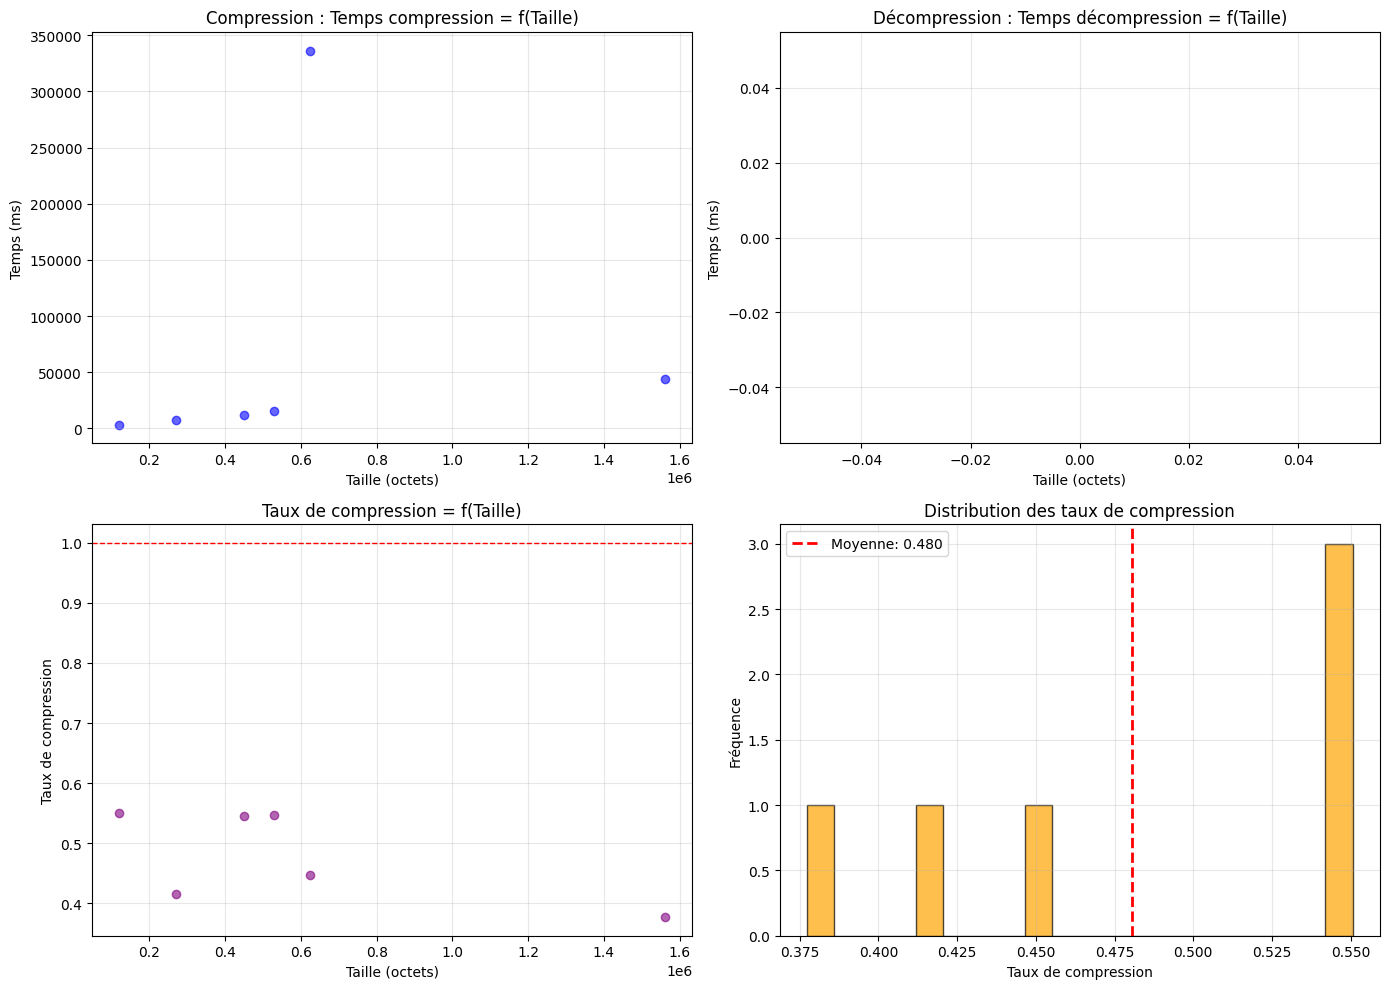

In [18]:
try:
    print_statistics()
    plot_all_stats()
except FileNotFoundError:
    print("Des cellules précédentes n'ont pas été exécutées")

## Résultats expérimentaux sur fichiers textuels générés (question 9)
On se sert à présent de fichiers textuels qu'on génère aléatoirement grâce au script generer.sh 
(cf rapport pour explication plus détaillée de celui-ci)

In [ ]:
!../generer.sh --help

Si on veut uniquement les informations de compression des fichiers aléatoires  


In [ ]:
!echo -n > ../compression.txt && echo -n > ../decompression.txt

In [85]:
!../generer.sh 10 random 

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 10
Base des noms      : random

Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random4.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random0.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random7.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random3.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random8.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random1.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random6.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random5.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/git/Huffman-Dynamique/texts/random2.txt' généré (13000 caractères).
Fichier aléatoire '/Users/user/g

In [24]:
!../generer.sh 5 random0 5000

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 5
Base des noms      : random0
Taille par fichier : 5000 caractères

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random02.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random00.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random01.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random03.txt' généré (5000 caractères).
Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random04.txt' généré (5000 caractères).

5 fichiers générés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts

COMPRESSION DES FICHIERS
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random00.huff
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random01.huff
Le fichier de sortie n'existai

In [25]:
!../generer.sh 3 random00 10000 'latin:0.7,emojis:0.2'

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 3
Base des noms      : random00
Taille par fichier : 10000 caractères
Distribution       : latin:0.7,emojis:0.2

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random001.txt' généré (10000 caractères).Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random000.txt' généré (10000 caractères).

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random002.txt' généré (10000 caractères).

3 fichiers générés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts

COMPRESSION DES FICHIERS
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random000.huff
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random001.huff
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random002.huff
Compression random00.txt ...
Compression random000.txt ...
Compression random001.txt ...
Compression random002.txt ...
Fichier encodé a

In [26]:
!../generer.sh 1 random000 1000 'latin:0,emojis:0.2,japanese:0.5,korean:0.2'

GÉNÉRATION DES FICHIERS
Nombre de fichiers : 1
Base des noms      : random000
Taille par fichier : 1000 caractères
Distribution       : latin:0,emojis:0.2,japanese:0.5,korean:0.2

Fichier aléatoire '/Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/random0000.txt' généré (1000 caractères).

1 fichiers générés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts

COMPRESSION DES FICHIERS
Le fichier de sortie n'existait pas, il a été créé : ./bintexts/random0000.huff
Compression random000.txt ...
Compression random0000.txt ...
Fichier encodé avec succès: random0000.txt -> ./bintexts/random0000.huff
Fichier encodé avec succès: random000.txt -> ./bintexts/random000.huff

Tous les fichiers ont été compressés dans /Users/thibaut/Desktop/M1/S1/ALGAV/Huffman-Dynamique/texts/bintexts


STATISTIQUES DE COMPRESSION
Nombre de fichiers : 209
Taux moyen : 0.72117
Temps moyen : 5352.55 ms
Taille moyenne entrée : 54547 octets
Réduction moyenne : 27.88%

STATISTIQUES DE DÉCOMPRESSION
Nombre de fichiers : 0
Temps moyen : nan ms

La décompression est nanx plus rapide que la compression
Graphique sauvegardé : analyse_complete.png


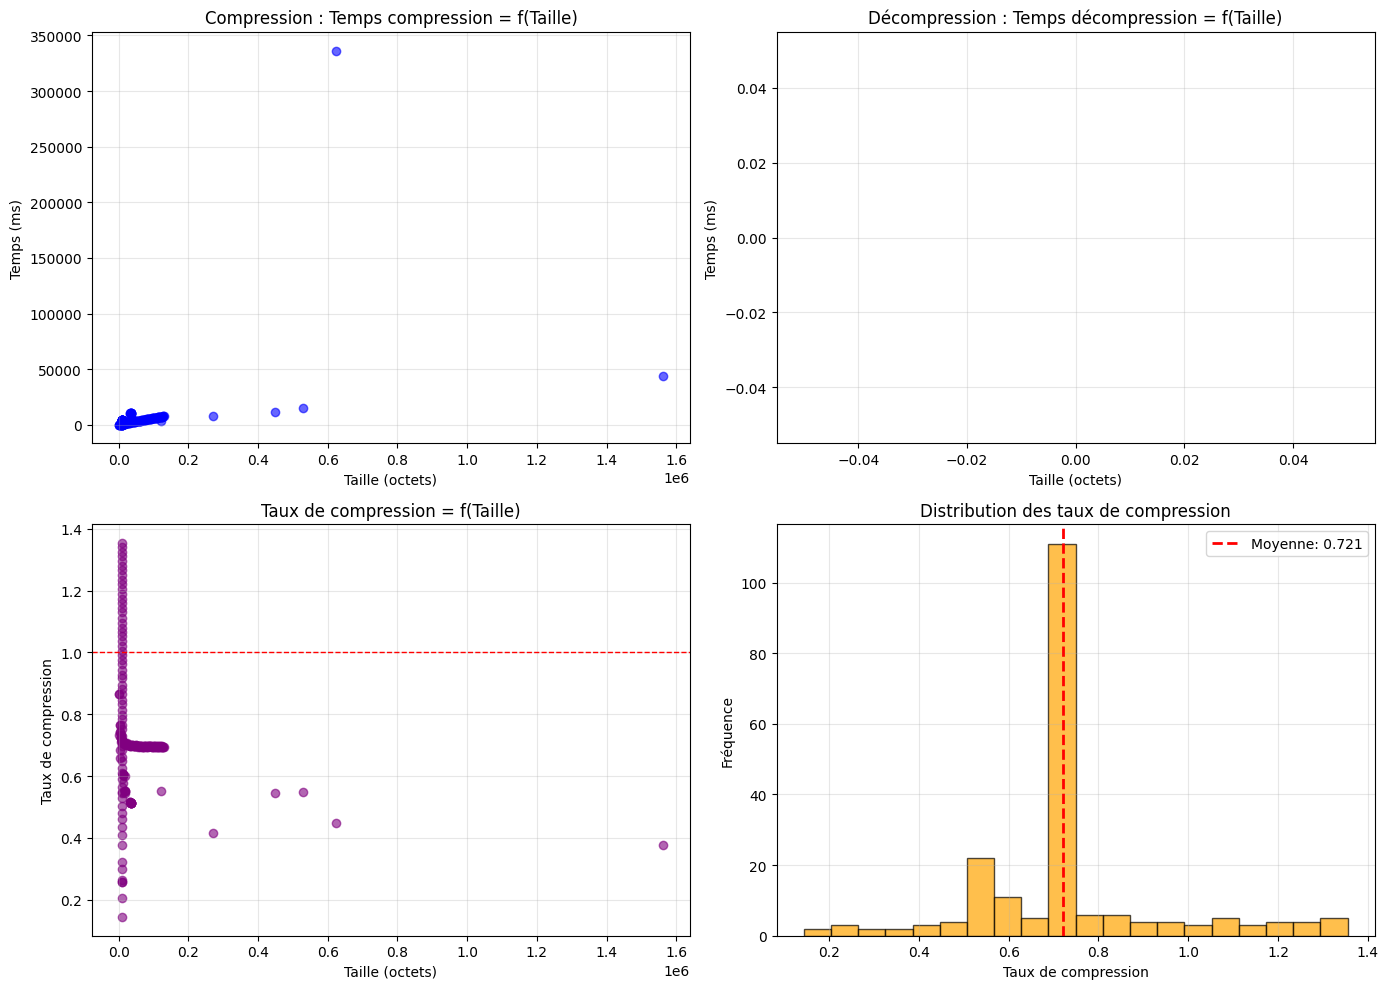

In [10]:
try:
    print_statistics()
    plot_all_stats()
except FileNotFoundError:
    print("Des cellules précédentes n'ont pas été exécutées")

## Résultats expérimentaux sur fichiers non textuels (question 10) ###
Enfin, on fait nos dernières expérimentations en utilisant des fichiers qui contiennent
de l’information sous une autre forme : du code. 

On utilise ici des fichiers .py, .sh, .ipynb, .md : on se servira tout simplement de fichiers de code présent dans ce projet.


In [ ]:
# si on veut uniquement les informations de compression des fichiers non textuels  
!echo -n > ../compression.txt && echo -n > ../decompression.txt

#### generate.py -- autour de 1 seconde

In [28]:
!../compresser ../src/generate.py ../texts/bintexts/generate.huff 

Compression ../src/generate.py ...
Fichier encodé avec succès: ../src/generate.py -> ../texts/bintexts/generate.huff


#### Node.py -- autour de 0.5 seconde

In [29]:
!../compresser ../src/Node.py ../texts/bintexts/Node.huff

Compression ../src/Node.py ...
Fichier encodé avec succès: ../src/Node.py -> ../texts/bintexts/Node.huff


#### utils.py -- autour de 0.5 seconde

In [30]:
!../compresser ../src/utils.py ../texts/bintexts/utils.huff

Compression ../src/utils.py ...
Fichier encodé avec succès: ../src/utils.py -> ../texts/bintexts/utils.huff


#### tests/test.ipynb -- autour de 0.7 seconde

In [31]:
!../compresser ../tests/tests.ipynb ../texts/bintexts/tests.ipynb

Compression ../tests/tests.ipynb ...
Fichier encodé avec succès: ../tests/tests.ipynb -> ../texts/bintexts/tests.ipynb


#### README.md -- autour de 0.3 seconde

In [32]:
!../compresser ../README.md ../texts/bintexts/README.huff

Compression ../README.md ...
Fichier encodé avec succès: ../README.md -> ../texts/bintexts/README.huff


#### generer.sh -- autour de 0.3 seconde

In [33]:
!../compresser ../generer.sh ../texts/bintexts/generer.huff

Compression ../generer.sh ...
Fichier encodé avec succès: ../generer.sh -> ../texts/bintexts/generer.huff


STATISTIQUES DE COMPRESSION
Nombre de fichiers : 209
Taux moyen : 0.72117
Temps moyen : 5352.55 ms
Taille moyenne entrée : 54547 octets
Réduction moyenne : 27.88%

STATISTIQUES DE DÉCOMPRESSION
Nombre de fichiers : 0
Temps moyen : nan ms

La décompression est nanx plus rapide que la compression
Graphique sauvegardé : analyse_complete.png


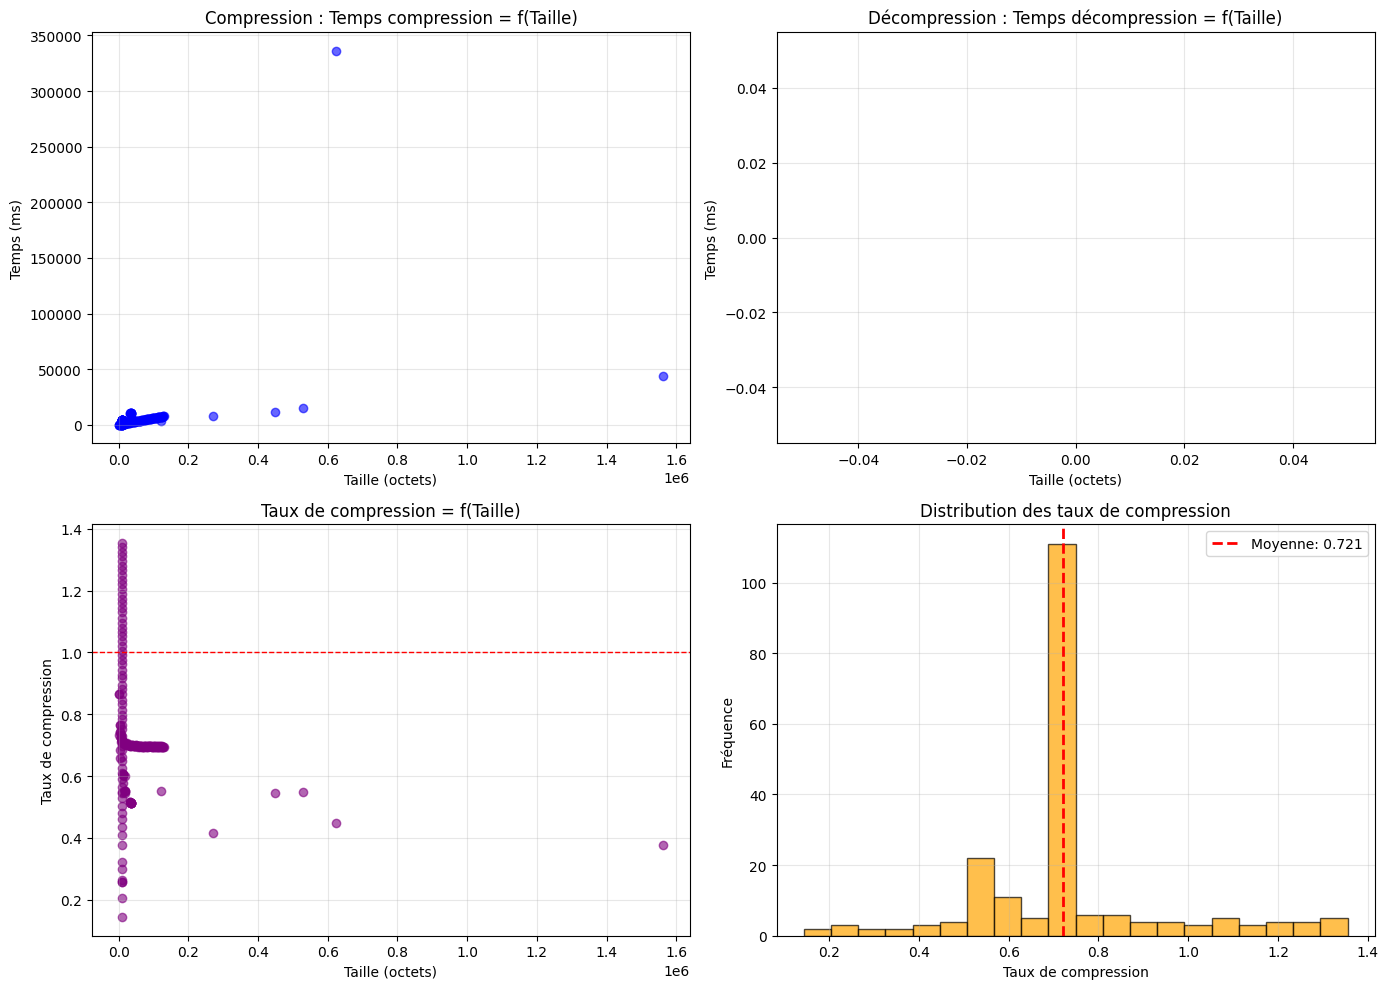

In [9]:
try:
    print_statistics()
    plot_all_stats()
except FileNotFoundError:
    print("Des cellules précédentes n'ont pas été exécutées")

## entropie etc

In [ ]:
# // Compter le nb de caractères uniques
!python3 -c "with open('../texts/analyse/symboles/sym_5000.txt', 'r', encoding='utf-8') as f: content = f.read(); unique_symbols = set(content); print(f'Nombre de symboles différents(taille alphabet): {len(unique_symbols)}')"

Traceback (most recent call last):
  File "<string>", line 1, in <module>
    with open('../texts/analyse/symboles/sym_*.txt', 'r', encoding='utf-8') as f: content = f.read(); unique_symbols = set(content); print(f'Nombre de symboles différents(taille alphabet): {len(unique_symbols)}')
         ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '../texts/analyse/symboles/sym_*.txt'


Nombre de fichiers trouvés: 110
Plage de longueurs: 1000 - 100000
Plage de temps: 92.43 - 7734.32 ms


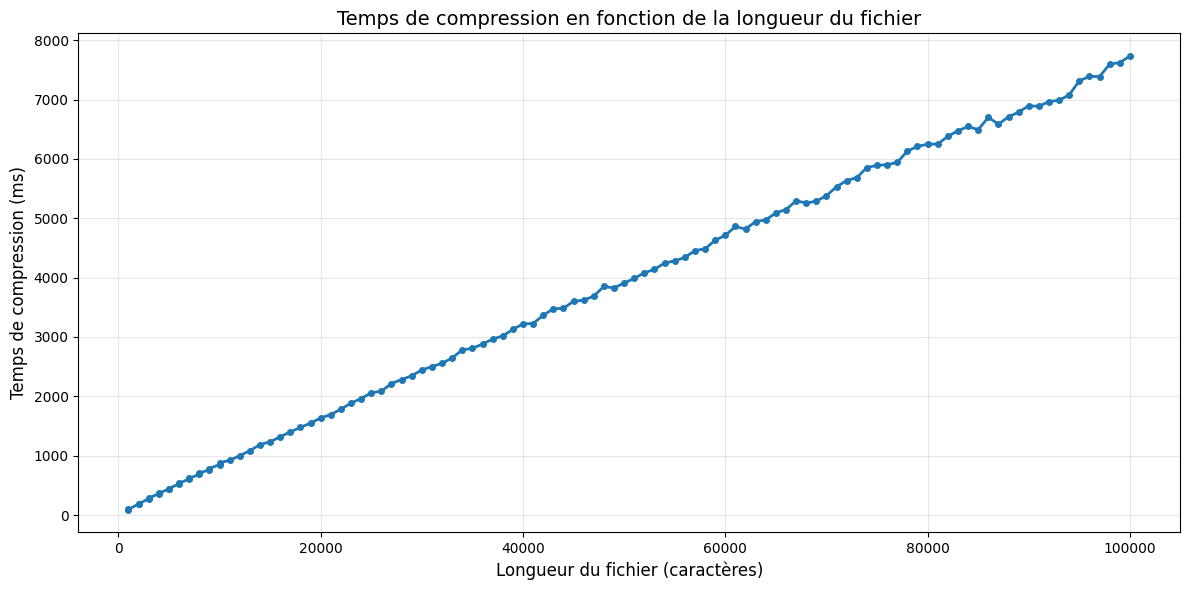

In [12]:
import matplotlib.pyplot as plt
import re

# Lire le fichier de compression
data = []
with open('../compression.txt', 'r') as f:
    for line in f:
        # Chercher les lignes qui correspondent aux fichiers analyse/len_*.txt
        if 'analyse/len_' in line and '.txt' in line:
            parts = line.strip().split(';')
            filename = parts[0]
            # Extraire la longueur du nom du fichier (avec ou sans -0)
            match = re.search(r'len_(\d+)(?:-0)?\.txt', filename)
            if match:
                length = int(match.group(1))
                # La dernière valeur est le temps de compression
                compression_time = float(parts[-1])
                data.append((length, compression_time))

# Trier les données par longueur
data.sort(key=lambda x: x[0])

# Séparer les données pour le graphique
lengths = [d[0] for d in data]
times = [d[1] for d in data]

print(f"Nombre de fichiers trouvés: {len(data)}")
if data:
    print(f"Plage de longueurs: {min(lengths)} - {max(lengths)}")
    print(f"Plage de temps: {min(times):.2f} - {max(times):.2f} ms")

# Créer le graphique
plt.figure(figsize=(12, 6))
plt.plot(lengths, times, marker='o', linestyle='-', linewidth=2, markersize=4)
plt.xlabel('Longueur du fichier (caractères)', fontsize=12)
plt.ylabel('Temps de compression (ms)', fontsize=12)
plt.title('Temps de compression en fonction de la longueur du fichier', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Afficher le graphique
plt.show()


Nombre de fichiers trouvés: 65
Plage de longueurs: 10 - 3000
Plage de temps: 23.46 - 4527.09 ms


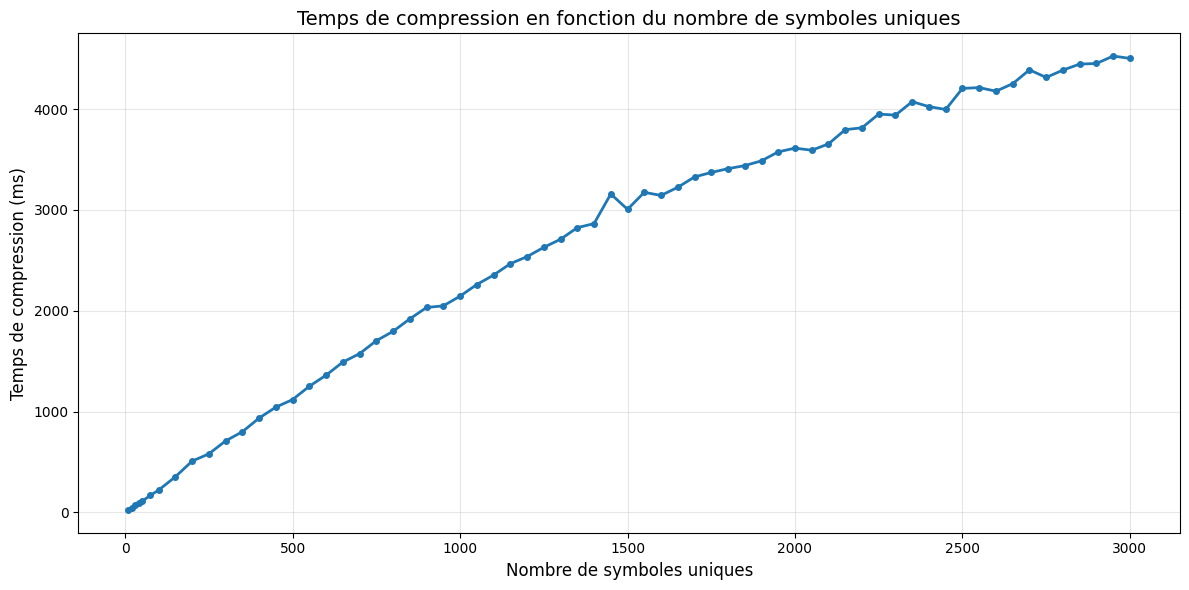

In [75]:
import matplotlib.pyplot as plt
import re

# Lire le fichier de compression
data = []
with open('../compression.txt', 'r') as f:
    for line in f:
        # Chercher les lignes qui correspondent aux fichiers analyse/symboles/sym_*.txt
        if 'analyse/symboles/sym_' in line and '.txt' in line:
            parts = line.strip().split(';')
            filename = parts[0]
            # Extraire la longueur du nom du fichier (avec ou sans -0)
            match = re.search(r'sym_(\d+)(?:-0)?\.txt', filename)
            if match:
                length = int(match.group(1))
                # La dernière valeur est le temps de compression
                compression_time = float(parts[-1])
                data.append((length, compression_time))

# Trier les données par longueur
data.sort(key=lambda x: x[0])

# Séparer les données pour le graphique
lengths = [d[0] for d in data]
times = [d[1] for d in data]

print(f"Nombre de fichiers trouvés: {len(data)}")
if data:
    print(f"Plage de longueurs: {min(lengths)} - {max(lengths)}")
    print(f"Plage de temps: {min(times):.2f} - {max(times):.2f} ms")

# Créer le graphique
plt.figure(figsize=(12, 6))
plt.plot(lengths, times, marker='o', linestyle='-', linewidth=2, markersize=4)
plt.xlabel('Nombre de symboles uniques', fontsize=12)
plt.ylabel('Temps de compression (ms)', fontsize=12)
plt.title('Temps de compression en fonction du nombre de symboles uniques', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Afficher le graphique
plt.show()


On veut visualiser des courbes du taux de compression en fonction de l'entropie. On fait varier l'entropie en prenant différents fichiers ; la plus grande entropie sera trouvée sur des fichiers les plus aléatoires possibles.

### thibaut calcule l'entropie

In [89]:
!python3 << 'PYTHON'
import math
from collections import Counter

# Lire le fichier
with open('../texts/francais.txt', 'r', encoding='utf-8') as f:
    text = f.read()
    

# Compter les caractères
char_counts = Counter(text)
total = len(text)

# Calculer l'entropie de Shannon
entropy = 0.0
for count in char_counts.values():
    p = count / total
    entropy -= p * math.log2(p)

print(f"Taille du fichier: {total} caractères")
print(f"Nombre de caractères uniques: {len(char_counts)}")
print(f"Entropie de Shannon: {entropy:.5f} bits")

# Afficher les 10 caractères les plus fréquents
print("\nTop 10 caractères les plus fréquents:")
for char, count in char_counts.most_common(10):
    p = count / total
    print(f"  '{char}': {count:6d} ({p*100:5.2f}%)")
#PYTHON

Taille du fichier: 505598 caractères
Nombre de caractères uniques: 117
Entropie de Shannon: 4.55361 bits

Top 10 caractères les plus fréquents:
  ' ':  75677 (14.97%)
  'e':  58307 (11.53%)
  'a':  30313 ( 6.00%)
  's':  29243 ( 5.78%)
  't':  29077 ( 5.75%)
  'i':  28346 ( 5.61%)
  'r':  25934 ( 5.13%)
  'n':  25077 ( 4.96%)
  'u':  24824 ( 4.91%)
  'l':  22536 ( 4.46%)


### creer graphes taux compression = f(entropie)

In [90]:
# =================== CALCUL ENTROPIE ===================

def file_to_text(filename="../compression.txt"):
    with open(filename, "r", encoding="utf-8") as f:
        text = f.read()
    return text

def calculate_entropy(text):
    """Calcule l'entropie de Shannon d'un texte"""
    # with open(filename, "r", encoding="utf-8") as f:
    #     text = f.read()
    if not text:
        return 0.0
    
    char_counts = Counter(text)
    total = len(text)
    entropy = 0.0
    
    for count in char_counts.values():
        p = count / total
        entropy -= p * math.log2(p)
    
    return entropy

def trouve_taux_comp(filename, logfile="../compression.txt"):
    """
    Trouve le taux de compression réel pour un fichier donné.
    Compare chemins absolus si possible, sinon fallback sur nom de fichier.
    """
    df = load_log_file(logfile)

    filename_abs = os.path.abspath(filename)
    filename_base = os.path.basename(filename)

    # Normalisation
    df['input_abs'] = df['input_file'].apply(lambda x: os.path.abspath(x) if os.path.exists(x) else None)
    df['input_base'] = df['input_file'].apply(os.path.basename)

    # matcher par chemin absolu
    row = df[df['input_abs'] == filename_abs]

    # fallback sur nom de fichier
    if row.empty:
        row = df[df['input_base'] == filename_base]

    if row.empty:
        return None

    return row['rate'].mean() * 100

def analyze_text(filename, logfile="../compression.txt"):
    """
    Analyse complète d'un texte et son taux de compression réel.
    """
    text = file_to_text(filename)

    entropy = calculate_entropy(text)
    char_counts = Counter(text)
    unique_chars = len(char_counts)
    total_chars = len(text)
    
    # Taux de compression avec notre Huffman
    taux_comp = trouve_taux_comp(filename, logfile)
    if taux_comp is None:
        print(f"--- Le fichier {filename} n'a pas été compressé auparavant : impossible de trouver taux compression")
        return None
    
    print(f"\n{'='*50}")
    print(f"Analyse: {filename}")
    print(f"{'='*50}")
    print(f"Taille: {total_chars} caractères")
    print(f"Caractères uniques: {unique_chars}")
    print(f"Entropie: {entropy:.4f} bits/caractère")
    print(f"Taux compression RÉEL (Huffman): {taux_comp:.2f}%")
    
    # Top 5 caractères
    print(f"\nTop 5 caractères:")
    for char, count in char_counts.most_common(5):
        p = count / total_chars
        char_display = repr(char) if char in ['\n', '\t', ' '] else char
        print(f"  {char_display}: {count:6d} ({p*100:5.2f}%)")
    
    return {
        'name': filename,
        'entropy': entropy,
        'taux_compression': taux_comp,
        'unique_chars': unique_chars
    }



def analyze_all_files(directory_name, logfile="../compression.txt"):
    """ lance analyze_text sur tous les fichiers de ce repertoire"""
    results = []
    
    for filename in glob(directory_name+"/**/*.txt", recursive=True): 
        result = analyze_text(filename, logfile)
        results.append(result)

    return results

# =================== VISUALISATION ===================
def plot_entropy_rate(results):
    entropies = []
    rates = []

    for r in results:
        if r is None:  # ignorer les analyses échouées
            continue
        if r.get('real_compression') is None:  # ignorer si pas de compression
            continue
        entropies.append(r['entropy'])
        rates.append(r['real_compression'])

    plt.figure(figsize=(8,5))
    plt.scatter(entropies, rates, color='orange', edgecolors='black', s=100, alpha=0.7)
    plt.xlabel("Entropie (bits/caractère)", fontsize=12, fontweight='bold')
    plt.ylabel("Taux de compression réel (%)", fontsize=12, fontweight='bold')
    plt.title("Compression réelle en fonction de l'entropie", fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_entropy_rate_with_shannon2(results):
    """
    Trace taux de compression réel en fonction de l'entropie
    et ajoute la limite théorique de Shannon.
    """
    entropies = [r['entropy'] for r in results if r['real_compression'] is not None]
    rates = [r['real_compression'] for r in results if r['real_compression'] is not None]

    plt.figure(figsize=(8,5))
    plt.scatter(entropies, rates, color='orange', edgecolors='black', s=100, alpha=0.7, label='Compression réelle')

    # Limite théorique de Shannon
    shannon_limit = [(h / 8) * 100 for h in entropies]
    plt.plot(entropies, shannon_limit, 'b--', linewidth=2, alpha=0.7, label='Limite Shannon')

    plt.xlabel("Entropie (bits/caractère)", fontsize=12, fontweight='bold')
    plt.ylabel("Taux de compression (%)", fontsize=12, fontweight='bold')
    plt.title("Compression réelle vs Limite théorique de Shannon", fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()



In [91]:
def plot_entropy_rate_with_shannon(results):
    """
    Trace taux de compression réel en fonction de l'entropie
    et ajoute la limite théorique de Shannon.
    """
    # Filtrer uniquement les résultats valides
    valid_results = [r for r in results if r is not None and r.get('real_compression') is not None]

    entropies = [r['entropy'] for r in valid_results]
    rates = [r['real_compression'] for r in valid_results]

    plt.figure(figsize=(8,5))
    plt.scatter(entropies, rates, color='orange', edgecolors='black', s=100, alpha=0.7, label='Compression réelle')

    # Limite théorique de Shannon
    shannon_limit = [(h / 8) * 100 for h in entropies]
    plt.plot(entropies, shannon_limit, 'b--', linewidth=2, alpha=0.7, label='Limite Shannon')

    plt.xlabel("Entropie (bits/caractère)", fontsize=12, fontweight='bold')
    plt.ylabel("Taux de compression (%)", fontsize=12, fontweight='bold')
    plt.title("Compression réelle vs Limite théorique de Shannon", fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


In [ ]:
res = analyze_all_files("../texts") # regarde tous les fichiers .txt du répertoire texts/
plot_entropy_rate(res)
plot_entropy_rate_with_shannon(res)

In [92]:
analyze_text("../texts/francais.txt")


Analyse: ../texts/francais.txt
Taille: 505598 caractères
Caractères uniques: 117
Entropie: 4.5536 bits/caractère
Taux compression RÉEL (Huffman): 54.74%

Top 5 caractères:
  ' ':  75677 (14.97%)
  e:  58307 (11.53%)
  a:  30313 ( 6.00%)
  s:  29243 ( 5.78%)
  t:  29077 ( 5.75%)


{'name': '../texts/francais.txt',
 'entropy': 4.553612459523404,
 'taux_compression': np.float64(54.742000000000004),
 'unique_chars': 117}

In [ ]:
analyze_text("../texts/chinois.txt")

In [87]:
!../compresser ../tests/very_low_entropy.txt ../texts/bintexts/very_low_entropy.huff
!../compresser ../tests/very_high_entropy.txt ../texts/bintexts/very_high_entropy.huff

Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/very_low_entropy.huff
Compression ../tests/very_low_entropy.txt ...
Fichier encodé avec succès: ../tests/very_low_entropy.txt -> ../texts/bintexts/very_low_entropy.huff
Le fichier de sortie n'existait pas, il a été créé : ../texts/bintexts/very_high_entropy.huff
Compression ../tests/very_high_entropy.txt ...
Fichier encodé avec succès: ../tests/very_high_entropy.txt -> ../texts/bintexts/very_high_entropy.huff



Analyse: ../tests/very_low_entropy.txt
Taille: 10000 caractères
Caractères uniques: 1
Entropie: 0.0000 bits/caractère
Taux compression théorique: 0.00%
Taux compression RÉEL (Huffman): 12.51%
Écart théorique/réel: 12.51%

Top 5 caractères:
  a:  10000 (100.00%)

Analyse: ../tests/very_high_entropy.txt
Taille: 10000 caractères
Caractères uniques: 95
Entropie: 6.5637 bits/caractère
Taux compression théorique: 82.05%
Taux compression RÉEL (Huffman): 84.35%
Écart théorique/réel: 2.30%

Top 5 caractères:
  q:    128 ( 1.28%)
  M:    124 ( 1.24%)
  p:    124 ( 1.24%)
  d:    122 ( 1.22%)
  [:    122 ( 1.22%)


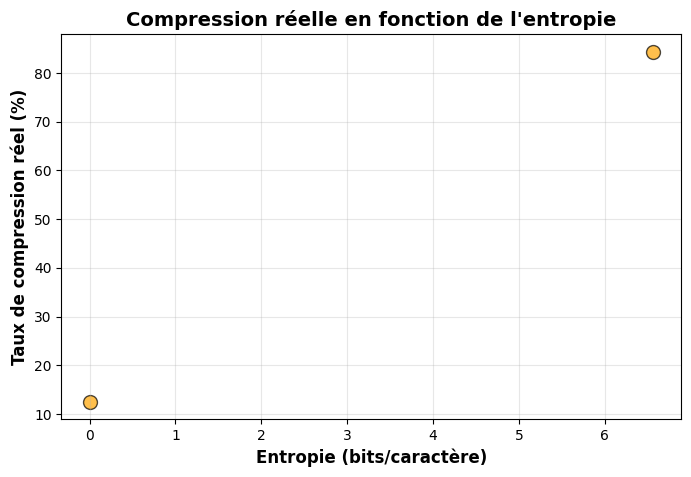

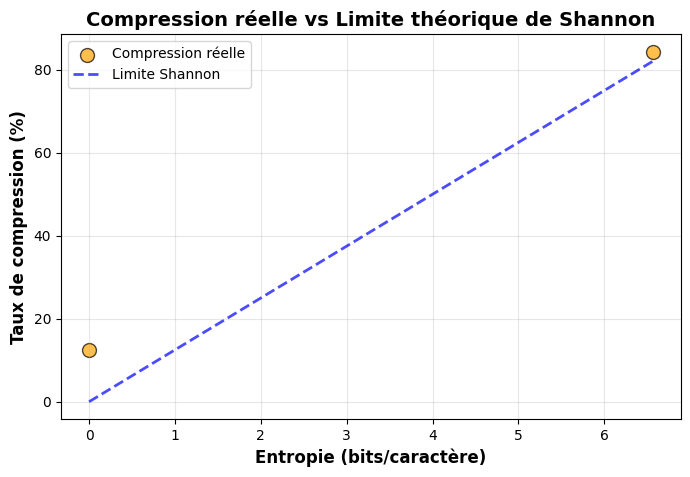

In [88]:
res = analyze_all_files("../tests") # regarde tous les fichiers .txt du répertoire texts/
plot_entropy_rate(res)
plot_entropy_rate_with_shannon(res)